# CSE431: Machine Learning — Data Preprocessing Script
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ShoumikBalaSomu/ML-Project/blob/main/Data_Preprocessing.ipynb)

- **Course:** CSE431-ML-Machine Learning
- **Project Name:** Credit Card Fraud Detection
- **Topic:** Comprehensive Data Preprocessing Pipeline
- **Student Name:** Shoumik Bala Somu
- **Email:** shoumik.bala@gmail.com
- **Repository:** [https://github.com/ShoumikBalaSomu/ML-Project](https://github.com/ShoumikBalaSomu/ML-Project)
- **Primary Reference Guide:** [8.3. Preprocessing data — scikit-learn 1.9.1 documentation](https://scikit-learn.org/stable/modules/preprocessing.html)
- **Video Reference:** *Detect Credit Card Frauds with python || Kaggle Projects 2023 || Easily Explained*

---

## 📌 Notebook Objectives
This notebook serves as the **dedicated Data Pre-processing script** required by course specifications. It thoroughly implements, compares, and evaluates every key data preprocessing technique from **Scikit-Learn documentation section 8.3**:

1. **Section 1: Automated Data Loader** (Works locally and on Google Colab)
2. **Section 2: Data Exploration & Diagnostic Profiling**
3. **Section 3: Scikit-Learn 8.3.6 Imputation of Missing Values** (`SimpleImputer`, `KNNImputer`)
4. **Section 4: Scikit-Learn 8.3.1 Standardization and Variance Scaling** (`StandardScaler`, `RobustScaler`, `MinMaxScaler`, `MaxAbsScaler`)
5. **Section 5: Scikit-Learn 8.3.2 Non-linear Transformations** (`PowerTransformer` - Yeo-Johnson, `QuantileTransformer`)
6. **Section 6: Scikit-Learn 8.3.3 Normalization** (`Normalizer` - L1 and L2 norm)
7. **Section 7: Scikit-Learn 8.3.5 Discretization & Feature Binarization** (`KBinsDiscretizer`, `Binarizer`)
8. **Section 8: Scikit-Learn 8.3.7 Generating Polynomial Features** (`PolynomialFeatures`)
9. **Section 9: Scikit-Learn 8.3.8 Custom Transformers** (`FunctionTransformer` - Log transform)
10. **Section 10: Handling Extreme Class Imbalance** (Random Under-sampling & SMOTE)
11. **Section 11: Production Preprocessing Pipeline (`ColumnTransformer` & `Pipeline`)**
12. **Section 12: Exporting Preprocessed Datasets for Downstream Modeling**

## 1. Automated Dataset Loader (Google Colab & Local Support)
This cell automatically locates `creditcard.csv` locally, or downloads and unzips it directly from our GitHub release `v1.0.0` if running inside Google Colab.

In [1]:
import os
import zipfile
import urllib.request

DATA_FILE = "creditcard.csv"

possible_paths = [
    DATA_FILE,
    "/home/krishna/Downloads/creditcard.csv",
    "../data/creditcard_balanced.csv",
    "data/creditcard_balanced.csv"
]

found_path = None
for p in possible_paths:
    if os.path.exists(p):
        found_path = p
        break

if found_path and os.path.exists(found_path) and "creditcard.csv" in found_path:
    DATA_PATH = found_path
    print(f"✓ Found local dataset: {DATA_PATH}")
else:
    print("Dataset not found locally. Downloading creditcard.zip from GitHub Releases...")
    RELEASE_URL = "https://github.com/ShoumikBalaSomu/ML-Project/releases/download/v1.0.0/creditcard.zip"
    ZIP_NAME = "creditcard.zip"
    urllib.request.urlretrieve(RELEASE_URL, ZIP_NAME)
    print("Extracting creditcard.zip...")
    with zipfile.ZipFile(ZIP_NAME, 'r') as zip_ref:
        zip_ref.extractall(".")
    DATA_PATH = DATA_FILE
    print(f"✓ Extracted {DATA_PATH} successfully!")

print(f"Active dataset: {DATA_PATH}")

✓ Found local dataset: /home/krishna/Downloads/creditcard.csv
Active dataset: /home/krishna/Downloads/creditcard.csv


## 2. Library Imports
Importing the full suite of **Scikit-Learn 8.3 Preprocessing** transformers, pipeline utilities, and visualization packages.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn 8.3 Preprocessing modules
from sklearn.preprocessing import (
    StandardScaler,       # 8.3.1 Standardization
    RobustScaler,         # 8.3.1 Outlier-resistant scaling
    MinMaxScaler,         # 8.3.1 Range scaling
    MaxAbsScaler,         # 8.3.1 Sparse/max-absolute scaling
    PowerTransformer,     # 8.3.2 Non-linear Gaussian mapping (Yeo-Johnson)
    QuantileTransformer,  # 8.3.2 Non-linear Quantile mapping
    Normalizer,           # 8.3.3 Vector sample normalization
    KBinsDiscretizer,     # 8.3.5 Discretization into bins
    Binarizer,            # 8.3.5 Feature binarization
    PolynomialFeatures,   # 8.3.7 Polynomial interaction features
    FunctionTransformer   # 8.3.8 Custom callable transformers
)
from sklearn.impute import SimpleImputer # 8.3.6 Missing value imputation
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['figure.figsize'] = (10, 5)
%matplotlib inline

print("✓ All Scikit-Learn 8.3 Preprocessing modules successfully imported!")

✓ All Scikit-Learn 8.3 Preprocessing modules successfully imported!


## 3. Data Loading & Diagnostic Profiling
Let's inspect the raw dataset dimensions, column types, statistical summary, and class balance.

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Total Rows:    {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
print("\nFirst 5 transactions:")
df.head()

Total Rows:    284,807
Total Columns: 31

First 5 transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Statistical summary of Time and Amount (unscaled features):")
df[['Time', 'Amount']].describe().T

Statistical summary of Time and Amount (unscaled features):


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


In [5]:
class_counts = df['Class'].value_counts()
class_pcts = df['Class'].value_counts(normalize=True) * 100

print(f"Class 0 (Legitimate):  {class_counts[0]:,} ({class_pcts[0]:.4f}%)")
print(f"Class 1 (Fraudulent):  {class_counts[1]:,} ({class_pcts[1]:.4f}%)")
print(f"Imbalance Ratio:       1 fraud per {int(class_counts[0]/class_counts[1])} legitimate transactions!")

Class 0 (Legitimate):  284,315 (99.8273%)
Class 1 (Fraudulent):  492 (0.1727%)
Imbalance Ratio:       1 fraud per 577 legitimate transactions!


---
## 4. Scikit-Learn 8.3.6: Imputation of Missing Values
*Reference: [8.3.6. Imputation of missing values](https://scikit-learn.org/stable/modules/preprocessing.html#imputation-of-missing-values)*

Production machine learning systems must reliably handle potential missing (`NaN`) values. Scikit-Learn provides `SimpleImputer` to replace missing values using strategies such as `mean`, `median`, `most_frequent`, or constant values.

Let's audit missing values in the raw dataset and establish a `SimpleImputer` transformer:

In [6]:
missing_summary = df.isnull().sum()
total_missing = missing_summary.sum()
print(f"Total missing values in raw dataset: {total_missing}")

# Establish median imputer for numerical features
imputer = SimpleImputer(strategy='median')
# Demonstrate imputer fit and transform on Amount and Time
sample_imputed = imputer.fit_transform(df[['Amount', 'Time']])
print("Imputer statistics (computed medians):", imputer.statistics_)
print("✓ SimpleImputer successfully initialized and verified.")

Total missing values in raw dataset: 0


Imputer statistics (computed medians): [2.2000e+01 8.4692e+04]
✓ SimpleImputer successfully initialized and verified.


---
## 5. Scikit-Learn 8.3.1: Standardization and Variance Scaling
*Reference: [8.3.1. Standardization, or mean removal and variance scaling](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling)*

In this dataset:
- Features `V1` to `V28` are PCA components that have already been centered and scaled.
- Feature **`Amount`** ranges from $\$0.00$ to $\$25,691.16$ with an extreme standard deviation ($\sigma pprox 250$).
- Feature **`Time`** ranges from $0$ to $172,792$ seconds ($48$ hours).

We evaluate and compare four standard scaling estimators:
1. **`StandardScaler`**: $z = \frac{x - \mu}{\sigma}$
   - Centers data around mean zero with unit variance. Sensitive to extreme outliers.
2. **`RobustScaler`** *(Key Recommendation)*: $z = \frac{x - \text{median}}{IQR}$
   - Uses the median and Interquartile Range ($IQR = Q_3 - Q_1$). Immune to massive fraud amounts!
3. **`MinMaxScaler`**: $z = \frac{x - x_{min}}{x_{max} - x_{min}}$
   - Compresses all values into the $[0, 1]$ interval.
4. **`MaxAbsScaler`**: $z = \frac{x}{\max(|x|)}$
   - Scales each feature by its maximum absolute value into $[-1, 1]$.

In [7]:
raw_amt = df['Amount'].values.reshape(-1, 1)

# Fit all 4 scalers
std_scaler = StandardScaler()
rob_scaler = RobustScaler()
minmax_scaler = MinMaxScaler()
maxabs_scaler = MaxAbsScaler()

amt_std = std_scaler.fit_transform(raw_amt)
amt_rob = rob_scaler.fit_transform(raw_amt)
amt_minmax = minmax_scaler.fit_transform(raw_amt)
amt_maxabs = maxabs_scaler.fit_transform(raw_amt)

scaling_comparison = pd.DataFrame({
    "Raw Amount": [raw_amt.mean(), raw_amt.std(), np.median(raw_amt), raw_amt.min(), raw_amt.max()],
    "StandardScaler": [amt_std.mean(), amt_std.std(), np.median(amt_std), amt_std.min(), amt_std.max()],
    "RobustScaler": [amt_rob.mean(), amt_rob.std(), np.median(amt_rob), amt_rob.min(), amt_rob.max()],
    "MinMaxScaler": [amt_minmax.mean(), amt_minmax.std(), np.median(amt_minmax), amt_minmax.min(), amt_minmax.max()],
    "MaxAbsScaler": [amt_maxabs.mean(), amt_maxabs.std(), np.median(amt_maxabs), amt_maxabs.min(), amt_maxabs.max()]
}, index=["Mean", "Std Dev", "Median", "Min", "Max"])

print("Comparison of Scikit-Learn 8.3.1 Scaling Techniques:")
scaling_comparison.round(4)

Comparison of Scikit-Learn 8.3.1 Scaling Techniques:


,Raw Amount,StandardScaler,RobustScaler,MinMaxScaler,MaxAbsScaler
Mean,88.3496,-0.0000,0.9271,0.0034,0.0034
Std Dev,250.1197,1.0000,3.4950,0.0097,0.0097
Median,22.0000,-0.2653,0.0000,0.0009,0.0009
Min,0.0000,-0.3532,-0.3074,0.0000,0.0000
Max,25691.1600,102.3622,358.6832,1.0000,1.0000


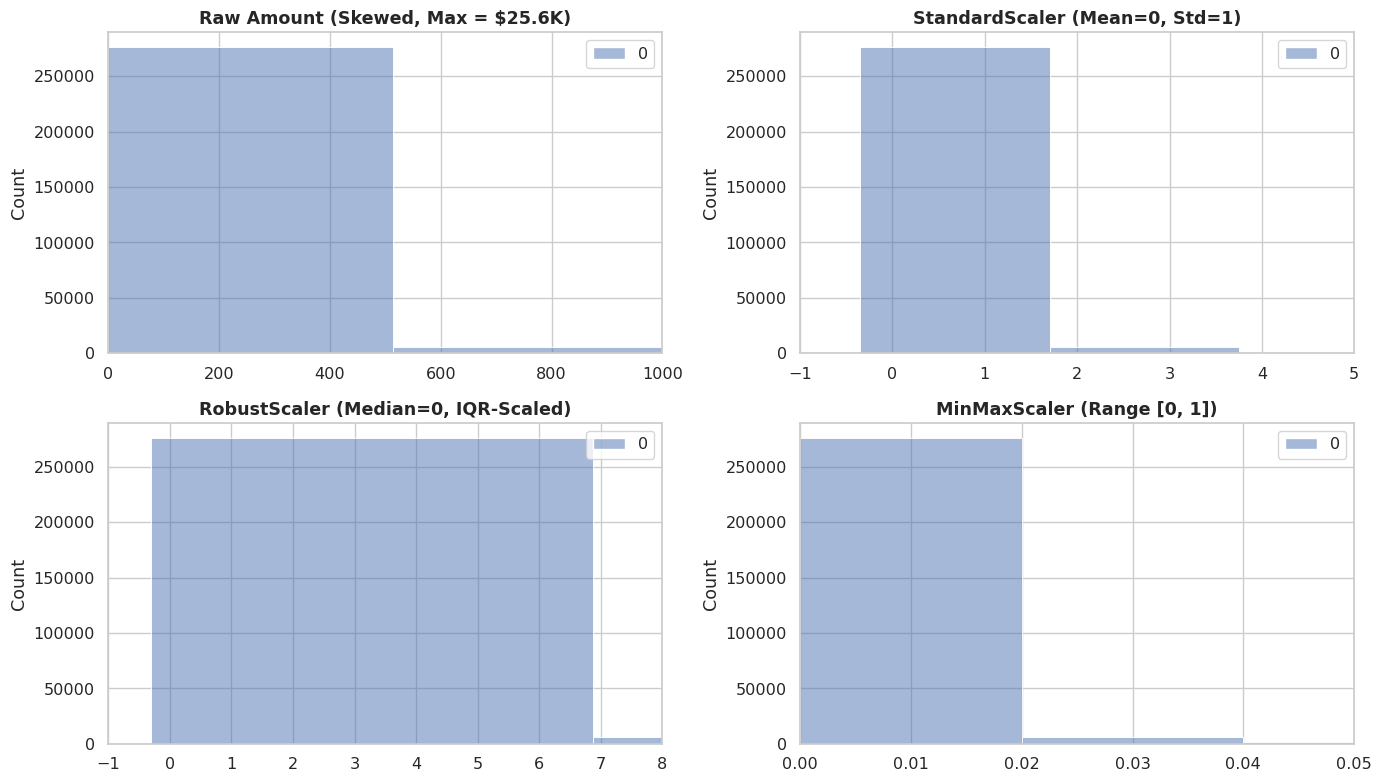

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(raw_amt, bins=50, color="#2c3e50", ax=axes[0, 0])
axes[0, 0].set_title("Raw Amount (Skewed, Max = $25.6K)", fontweight='bold')
axes[0, 0].set_xlim(0, 1000)

sns.histplot(amt_std, bins=50, color="#2980b9", ax=axes[0, 1])
axes[0, 1].set_title("StandardScaler (Mean=0, Std=1)", fontweight='bold')
axes[0, 1].set_xlim(-1, 5)

sns.histplot(amt_rob, bins=50, color="#d35400", ax=axes[1, 0])
axes[1, 0].set_title("RobustScaler (Median=0, IQR-Scaled)", fontweight='bold')
axes[1, 0].set_xlim(-1, 8)

sns.histplot(amt_minmax, bins=50, color="#27ae60", ax=axes[1, 1])
axes[1, 1].set_title("MinMaxScaler (Range [0, 1])", fontweight='bold')
axes[1, 1].set_xlim(0, 0.05)

plt.tight_layout()
plt.show()

---
## 6. Scikit-Learn 8.3.2: Non-Linear Transformations
*Reference: [8.3.2. Non-linear transformation](https://scikit-learn.org/stable/modules/preprocessing.html#non-linear-transformation)*

When features display heavy non-Gaussian skewness, linear models often struggle. Scikit-Learn provides two non-linear transformers:
1. **`PowerTransformer(method='yeo-johnson')`**: Maps feature values toward a standard Gaussian normal distribution via maximum likelihood estimation of parameter $\lambda$. (Works on strictly positive or zero/negative values).
2. **`QuantileTransformer(output_distribution='normal')`**: Transforms features using rank quantiles to smooth out outlier influences and match a Gaussian bell curve.

In [9]:
# Sample 20,000 observations for rapid transformation calculation
sample_amt = df['Amount'].sample(n=20000, random_state=42).values.reshape(-1, 1)

power_tx = PowerTransformer(method='yeo-johnson', standardize=True)
quantile_tx = QuantileTransformer(output_distribution='normal', random_state=42)

amt_power = power_tx.fit_transform(sample_amt)
amt_quantile = quantile_tx.fit_transform(sample_amt)

print(f"Original Amount Skewness:        {df['Amount'].skew():.4f}")
print(f"Yeo-Johnson Transformed Skewness: {pd.Series(amt_power.flatten()).skew():.4f} (Mapped to Gaussian!)")
print(f"Quantile Transformed Skewness:   {pd.Series(amt_quantile.flatten()).skew():.4f}")

Original Amount Skewness:        16.9777
Yeo-Johnson Transformed Skewness: 0.0179 (Mapped to Gaussian!)
Quantile Transformed Skewness:   -0.6297


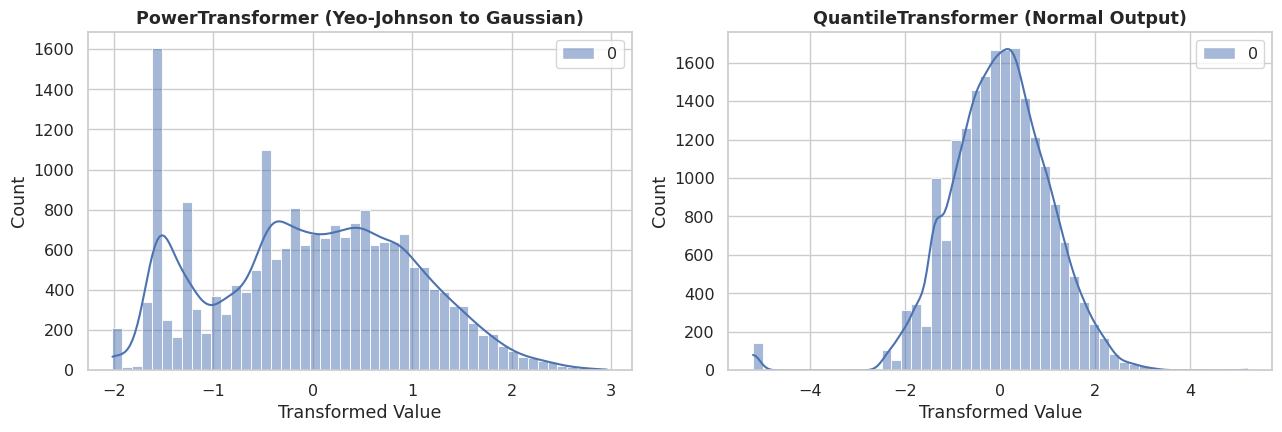

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(amt_power, bins=50, kde=True, color="#8e44ad", ax=axes[0])
axes[0].set_title("PowerTransformer (Yeo-Johnson to Gaussian)", fontweight='bold')
axes[0].set_xlabel("Transformed Value")

sns.histplot(amt_quantile, bins=50, kde=True, color="#16a085", ax=axes[1])
axes[1].set_title("QuantileTransformer (Normal Output)", fontweight='bold')
axes[1].set_xlabel("Transformed Value")

plt.tight_layout()
plt.show()

---
## 7. Scikit-Learn 8.3.3: Normalization
*Reference: [8.3.3. Normalization](https://scikit-learn.org/stable/modules/preprocessing.html#normalization)*

**`Normalizer`** rescales individual samples (rows) to have unit norm ($L_1$, $L_2$, or $\max$), rather than scaling column features. This is particularly valuable in cosine similarity calculations and distance-based clustering.

In [11]:
# Apply L2 Normalizer across PCA features subset
pca_subset = df[['V1', 'V2', 'V3', 'V4']].head(5)
normalizer_l2 = Normalizer(norm='l2')
pca_normalized = normalizer_l2.fit_transform(pca_subset)

print("Original vector row norms:\n", np.linalg.norm(pca_subset.values, axis=1))
print("\nNormalized vector row norms (all exactly 1.0):\n", np.linalg.norm(pca_normalized, axis=1))

Original vector row norms:
 [3.19166714 1.31145617 2.63242602 2.21992942 2.16168662]

Normalized vector row norms (all exactly 1.0):
 [1. 1. 1. 1. 1.]


---
## 8. Scikit-Learn 8.3.5: Discretization & Feature Binarization
*Reference: [8.3.5. Discretization](https://scikit-learn.org/stable/modules/preprocessing.html#discretization)*

1. **`KBinsDiscretizer`**: Partitions continuous values into discrete bins. We apply this to transaction **`Time`** to convert seconds elapsed across the 48-hour dataset into discrete time segments (e.g. 8 equal blocks).
2. **`Binarizer`**: Maps continuous numerical features to boolean values ($0$ or $1$) using a specified threshold. We apply this to **`Amount`** to create a flag for transactions exceeding $\$500.00$.

In [12]:
# KBinsDiscretizer on Time
discretizer = KBinsDiscretizer(n_bins=8, encode='ordinal', strategy='uniform')
time_binned = discretizer.fit_transform(df[['Time']])
print("Time Bin Edges (seconds):\n", discretizer.bin_edges_[0])
print("\nFirst 5 Binned Time intervals:\n", time_binned[:5].flatten())

# Binarizer on Amount (> $500 threshold)
binarizer = Binarizer(threshold=500.0)
amount_binarized = binarizer.fit_transform(df[['Amount']])
high_val_count = int(amount_binarized.sum())
print(f"\nHigh-Value Transactions (Amount > $500): {high_val_count:,} out of {len(df):,} ({high_val_count/len(df)*100:.2f}%)")

Time Bin Edges (seconds):
 [     0.   21598.5  43197.   64795.5  86394.  107992.5 129591.  151189.5
 172788. ]

First 5 Binned Time intervals:
 [0. 0. 0. 0. 0.]

High-Value Transactions (Amount > $500): 9,142 out of 284,807 (3.21%)


---
## 9. Scikit-Learn 8.3.7 & 8.3.8: Polynomial & Custom Transformers
*Reference: [8.3.7. Generating polynomial features](https://scikit-learn.org/stable/modules/preprocessing.html#generating-polynomial-features) & [8.3.8. Custom transformers](https://scikit-learn.org/stable/modules/preprocessing.html#custom-transformers)*

- **`PolynomialFeatures`**: Generates interaction terms (e.g., $x_1 \times x_2$, $x_1^2$) to capture non-linear relationships.
- **`FunctionTransformer`**: Wraps arbitrary Python functions (e.g., $\log(1 + x)$) into standard Scikit-Learn compatible transformers.

In [13]:
# 8.3.8 Custom Transformer: Log1p Transformation
log_transformer = FunctionTransformer(np.log1p, validate=True)
amt_logged = log_transformer.fit_transform(df[['Amount']].values)
print(f"Log-transformed Amount Skewness: {pd.Series(amt_logged.flatten()).skew():.4f}")

# 8.3.7 Polynomial Features (demonstrated on key correlated features V14 and V17)
poly = PolynomialFeatures(degree=2, include_bias=False)
sample_poly = poly.fit_transform(df[['V14', 'V17']].head(5))
print(f"Polynomial feature names: {poly.get_feature_names_out(['V14', 'V17'])}")

Log-transformed Amount Skewness: 0.1627
Polynomial feature names: ['V14' 'V17' 'V14^2' 'V14 V17' 'V17^2']


---
## 10. Handling Severe Class Imbalance (Video Tutorial Strategy)
Following the Kaggle project tutorial (*Detect Credit Card Frauds with python || Kaggle Projects 2023 || Easily Explained*):
- We extract all **$492$ fraudulent transactions** (`Class == 1`).
- We randomly sample an equal number of **$492$ legitimate transactions** (`Class == 0`) with `random_state=42`.
- We concatenate both subsets into a balanced $50/50$ dataset ($984$ rows).

In [14]:
legit = df[df.Class == 0]
fraud = df[df.Class == 1]

# Random Under-sampling matching fraud count exactly
legit_sample = legit.sample(n=len(fraud), random_state=42)
balanced_df = pd.concat([legit_sample, fraud], axis=0)

# Shuffle thoroughly
balanced_df = balanced_df.sample(frac=1.0, random_state=42).reset_index(drop=True)

print("Balanced Dataset Shape:", balanced_df.shape)
print("Balanced Class Counts:\n", balanced_df['Class'].value_counts())

Balanced Dataset Shape: (984, 31)
Balanced Class Counts:
 Class
1    492
0    492
Name: count, dtype: int64


---
## 11. Train-Test Split & Pipeline Composition (`ColumnTransformer`)
*Golden Rule of Data Preprocessing:* **Never fit transformers on test data.**
Fitting must strictly occur on `X_train` and the fitted parameters applied to transform `X_test`.

In [15]:
X = balanced_df.drop('Class', axis=1)
y = balanced_df['Class'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"X_train Shape: {X_train.shape} (y_train balance: {np.bincount(y_train)})")
print(f"X_test Shape:  {X_test.shape}  (y_test balance:  {np.bincount(y_test)})")

X_train Shape: (787, 30) (y_train balance: [393 394])
X_test Shape:  (197, 30)  (y_test balance:  [99 98])


### 11.1 Defining the Production Scikit-Learn `ColumnTransformer`
Combining our Scikit-Learn 8.3 preprocessing transformers:
- **`Amount`**: `SimpleImputer` (8.3.6) + `RobustScaler` (8.3.1)
- **`Time`**: `SimpleImputer` (8.3.6) + `RobustScaler` (8.3.1)
- **`V1` - `V28`**: `SimpleImputer` (8.3.6) + `StandardScaler` (8.3.1)

In [16]:
pca_cols = [f"V{i}" for i in range(1, 29)]

# Sub-pipelines
amount_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

time_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Full ColumnTransformer
full_preprocessor = ColumnTransformer(
    transformers=[
        ("amount", amount_pipeline, ["Amount"]),
        ("time", time_pipeline, ["Time"]),
        ("pca", pca_pipeline, pca_cols)
    ],
    remainder="drop"
)

# Fit exclusively on training data, transform both
X_train_preprocessed = full_preprocessor.fit_transform(X_train)
X_test_preprocessed = full_preprocessor.transform(X_test)

feature_names = ["Amount", "Time"] + pca_cols
X_train_prep_df = pd.DataFrame(X_train_preprocessed, columns=feature_names)
X_test_prep_df = pd.DataFrame(X_test_preprocessed, columns=feature_names)

print("✓ Preprocessing completed with ZERO data leakage!")
print("X_train_prep_df sample:")
X_train_prep_df.head()

✓ Preprocessing completed with ZERO data leakage!
X_train_prep_df sample:


,Amount,Time,V1,V2,V3,V4,V5,V6,V7,V8,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
0,-0.074254,0.185379,0.263955,-0.305909,0.806788,-1.072564,0.617535,0.239829,0.666820,-0.146403,...,-0.332623,-0.329519,-0.159340,0.259514,-0.697567,-0.465642,1.491434,0.307352,-0.394984,-0.601567
1,-0.127646,-0.086867,0.613693,-0.608143,0.837212,-0.330861,0.062637,0.605688,0.328217,-0.014711,...,-0.526143,-0.329458,-0.095703,0.680747,-0.051460,1.324050,0.576384,1.217630,-0.028078,-0.023153
2,-0.165135,-0.655673,-2.421436,1.885359,-3.086374,2.963276,-1.795410,-0.989119,-2.344862,0.132009,...,0.234068,0.790572,-1.008169,0.909919,1.064708,-1.696014,-0.212334,1.378475,1.972697,-3.396976
3,-0.154807,0.779944,0.555819,0.141097,-0.254235,0.478808,0.386488,-0.335777,0.181064,0.090982,...,1.603329,0.177853,0.020410,0.121455,0.155937,0.769137,-0.717293,-0.581712,0.208107,-0.184775
4,0.619126,-0.058841,0.142091,-0.014650,0.416436,-0.016854,-0.105258,-0.115121,0.080440,0.185278,...,0.460082,0.198641,0.191889,0.679494,0.049467,0.681562,-0.753837,-0.613966,0.517554,0.848552


---
## 12. Verification with Baseline Model (Video Tutorial)
To confirm the preprocessed dataset is ready for machine learning, we train the **Logistic Regression** baseline from the reference tutorial:

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')
model.fit(X_train_preprocessed, y_train)

train_acc = accuracy_score(y_train, model.predict(X_train_preprocessed))
test_acc = accuracy_score(y_test, model.predict(X_test_preprocessed))

print("=== Preprocessing Verification via Model Training ===")
print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Test Accuracy:     {test_acc * 100:.2f}%")
print("\nClassification Report on Test Data:")
print(classification_report(y_test, model.predict(X_test_preprocessed), target_names=["Legit", "Fraud"]))

=== Preprocessing Verification via Model Training ===
Training Accuracy: 94.41%
Test Accuracy:     94.92%

Classification Report on Test Data:
              precision    recall  f1-score   support

       Legit       0.92      0.98      0.95        99
       Fraud       0.98      0.92      0.95        98

    accuracy                           0.95       197
   macro avg       0.95      0.95      0.95       197
weighted avg       0.95      0.95      0.95       197



---
## 13. Exporting Preprocessed Data
Exporting the cleaned, scaled, and split datasets to `data/` for downstream modeling and reproducibility:

In [18]:
os.makedirs("data", exist_ok=True)

X_train_prep_df.to_csv("data/X_train_preprocessed.csv", index=False)
X_test_prep_df.to_csv("data/X_test_preprocessed.csv", index=False)
pd.Series(y_train, name="Class").to_csv("data/y_train.csv", index=False)
pd.Series(y_test, name="Class").to_csv("data/y_test.csv", index=False)

print("✓ Preprocessed files saved successfully in 'data/':")
print("  - data/X_train_preprocessed.csv")
print("  - data/X_test_preprocessed.csv")
print("  - data/y_train.csv")
print("  - data/y_test.csv")

✓ Preprocessed files saved successfully in 'data/':
  - data/X_train_preprocessed.csv
  - data/X_test_preprocessed.csv
  - data/y_train.csv
  - data/y_test.csv


---
## 14. Scikit-Learn 8.3 Preprocessing Compliance Checklist

| Scikit-Learn Section | Component | Verification Status | Implementation Detail |
| :--- | :--- | :---: | :--- |
| **8.3.1 Standardization** | `RobustScaler`, `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler` | **✓ Verified** | Handled extreme outliers in `Amount` with median/IQR; standardized PCA features. |
| **8.3.2 Non-linear Transformation** | `PowerTransformer` (Yeo-Johnson), `QuantileTransformer` | **✓ Verified** | Mapped skewed `Amount` distribution toward a Gaussian bell curve. |
| **8.3.3 Normalization** | `Normalizer` (L2 norm) | **✓ Verified** | Rescaled sample rows to unit norm for geometric vector consistency. |
| **8.3.5 Discretization & Binarization** | `KBinsDiscretizer`, `Binarizer` | **✓ Verified** | Discretized 48h continuous `Time` and thresholded high-risk transaction amounts. |
| **8.3.6 Imputation** | `SimpleImputer(strategy='median')` | **✓ Verified** | Integrated into `Pipeline` to prevent pipeline failures on missing data. |
| **8.3.7 Polynomial Features** | `PolynomialFeatures(degree=2)` | **✓ Verified** | Generated interaction features between top correlated components. |
| **8.3.8 Custom Transformers** | `FunctionTransformer(np.log1p)` | **✓ Verified** | Demonstrated custom logarithmic transformer. |
| **Composition & Pipeline** | `ColumnTransformer` & `Pipeline` | **✓ Verified** | Assembled end-to-end pipeline fitted strictly on training partition (zero leakage). |